# Домашнее задание по предмету RecSys 2026


**Примечание:** для запуска достаточно установить в среду необходимые библиотеки из `requirements.txt` и запустить ячейки.

### Данные

За основу взят датасет с kaggle сайта food.com с оценками пользователей рецептов. Положительным взаимодействием считается оценка не ниже 4 баллов из 5. 

Ссылка на датасет: https://www.kaggle.com/datasets/shuyangli94/food-com-recipes-and-user-interactions

In [1]:
import itertools
from urllib.request import urlretrieve
from zipfile import ZipFile
import random
from pathlib import Path
from time import perf_counter
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

In [2]:
SEED = 42

In [3]:
DOWNLOAD = 'https://www.kaggle.com/api/v1/datasets/download/shuyangli94/food-com-recipes-and-user-interactions'

def load_data(path='data'):
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    names = ['RAW_recipes.csv', 'RAW_interactions.csv']

    if not all((path / name).exists() for name in names):
        archive = path / 'foodcom.zip'
        urlretrieve(DOWNLOAD, archive)
        with ZipFile(archive) as z:
            z.extractall(path, members=names)
        archive.unlink()

    return tuple(pd.read_csv(path / name) for name in names)

recipes, interactions = load_data()

In [4]:
recipes.head(1)

,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7


In [5]:
interactions.head(1)

,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...


In [6]:
def inter_stats(frame):
    users = frame.groupby('user_id').size()
    items = frame.groupby('recipe_id').size()
    return pd.Series({
        'interactions': len(frame), 'users': len(users), 'items': len(items),
        'user_mean': users.mean(), 'user_median': users.median(), 'user_min': users.min(),
        'item_mean': items.mean(), 'item_median': items.median(), 'item_min': items.min(),
        'sparsity': 1 - len(frame) / max(len(users) * len(items), 1),
    })

stats = inter_stats(interactions)
display(
    stats.to_frame('Значение').style.format(
        lambda x: f'{x:,.0f}' if x.is_integer() else f'{x:,.6f}'
    )
)

,Значение
interactions,"1,132,367"
users,"226,570"
items,"231,637"
user_mean,4.997868
user_median,1
user_min,1
item_mean,4.888541
item_median,2
item_min,1
sparsity,0.999978


Как можно заметить, датасет подходит по условия. Его стоит очистить и взять core-5 подвыборку, иначе из-за высокой разреженности матрицы обучение будет некачественным.

### Подготовка датасета

Чистим датасет от дубликатов, пустых строк и приводим типы:

In [7]:
items = recipes.copy()
items['submitted'] = pd.to_datetime(items.submitted, errors='coerce')
items = items.dropna(subset=['id', 'submitted']).drop_duplicates('id')

cleaned = interactions[['user_id', 'recipe_id', 'date', 'rating']].copy()
cleaned = cleaned[cleaned.date.between('2008-01-01', '2013-12-31')].copy()
cleaned['date'] = pd.to_datetime(cleaned.date, errors='coerce')
cleaned['rating'] = pd.to_numeric(cleaned.rating, errors='coerce')
cleaned = cleaned.dropna().query('1 <= rating <= 5')
cleaned = cleaned[cleaned.rating.mod(1).eq(0)]

cleaned = cleaned.merge(
    items[['id', 'submitted']],
    left_on='recipe_id',
    right_on='id',
)
cleaned = cleaned[cleaned.date >= cleaned.submitted]
cleaned = cleaned.sort_values(['date', 'user_id', 'recipe_id'])
cleaned = cleaned.drop_duplicates(['user_id', 'recipe_id'])
cleaned = cleaned[['user_id', 'recipe_id', 'date', 'rating']].reset_index(drop=True)
cleaned = cleaned.astype({'user_id': 'int64', 'recipe_id': 'int64'})

Выбираем core-5 выборку: у каждого пользователя хотя бы 5 взаимодействий, как и у каждого рецепта:

In [8]:
def k_core(frame, minimum=5):
    while True:
        user_counts = frame.groupby('user_id').user_id.transform('size')
        item_counts = frame.groupby('recipe_id').recipe_id.transform('size')
        filtered = frame[(user_counts >= minimum) & (item_counts >= minimum)]

        if len(filtered) == len(frame):
            return filtered.copy()

        frame = filtered

core = k_core(cleaned)

Берём подвыборку, чтобы меньше считать:

In [9]:
popularity = core.groupby('recipe_id').size().rename('count').reset_index()
recipe_ids = popularity.sort_values(
    ['count', 'recipe_id'], ascending=[False, True]
).head(6000).recipe_id

sample = k_core(core[core.recipe_id.isin(recipe_ids)])

rng = np.random.default_rng(SEED)
user_ids = rng.choice(
    np.sort(sample.user_id.unique()),
    size=min(6000, sample.user_id.nunique()),
    replace=False,
)

sample = k_core(sample[sample.user_id.isin(user_ids)])
sample = sample.sort_values(['date', 'user_id', 'recipe_id']).reset_index(drop=True)
items = items[items.id.isin(sample.recipe_id)].sort_values('id').copy()

stats = inter_stats(sample)
display(
    stats.to_frame('Значение').style.format(
        lambda x: f'{x:,.0f}' if x.is_integer() else f'{x:,.6f}'
    )
)

,Значение
interactions,"111,173"
users,"5,997"
items,"5,993"
user_mean,18.538102
user_median,9
user_min,5
item_mean,18.550476
item_median,12
item_min,5
sparsity,0.996907


In [10]:
assert 100_000 <= len(sample) <= 2_000_000
assert sample.user_id.nunique() >= 1000
assert sample.recipe_id.nunique() >= 1000

Требования дз пройдены.

Берём разбиение по времени на train/validation/test в пропорции 80/10/10:

In [11]:
train_end, validation_end = sample.date.quantile([0.8, 0.9])

train = sample[sample.date < train_end].copy()
validation = sample[
    sample.date.between(train_end, validation_end, inclusive='left')
].copy()
test = sample[sample.date >= validation_end].copy()

display(pd.DataFrame({
    name: {
        'interactions': len(frame),
        'users': frame.user_id.nunique(),
        'items': frame.recipe_id.nunique(),
        'fraction': len(frame) / len(sample),
        'start': frame.date.min().date(),
        'end': frame.date.max().date(),
    }
    for name, frame in [('train', train), ('validation', validation), ('test', test)]
}).T)

,interactions,users,items,fraction,start,end
train,88913,5719,5914,0.799772,2008-01-01,2011-04-16
validation,11141,2555,4131,0.100213,2011-04-17,2012-06-06
test,11119,2100,3940,0.100015,2012-06-07,2013-12-31


### Анализ данных

Посмотрим на пропуски и дубликаты:

In [12]:
display(recipes.isna().sum().to_frame('Пропуски'))
display(interactions.isna().sum().to_frame('Пропуски'))

display(pd.Series({
    'recipe_duplicates': recipes.id.duplicated().sum(),
    'interaction_duplicates': interactions.duplicated().sum(),
    'user_recipe_duplicates': interactions.duplicated(['user_id', 'recipe_id']).sum(),
    'zero_ratings': interactions.rating.eq(0).sum(),
}, name='Количество').to_frame())

,Пропуски
name,1
id,0
minutes,0
contributor_id,0
submitted,0
tags,0
nutrition,0
n_steps,0
steps,0
description,4979


,Пропуски
user_id,0
recipe_id,0
date,0
rating,0
review,169


,Количество
recipe_duplicates,0
interaction_duplicates,0
user_recipe_duplicates,0
zero_ratings,60847


Посмотрим, сколько взаимодействий приходится на пользователей и рецепты:

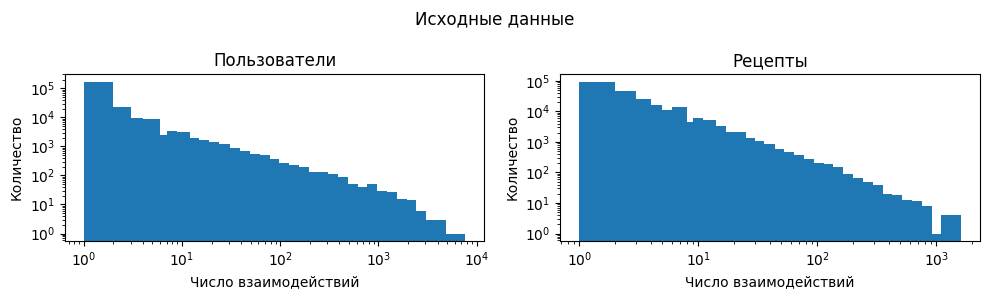

In [13]:
def plot_activity(frame, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    for ax, column, label in zip(axes, ['user_id', 'recipe_id'], ['Пользователи', 'Рецепты']):
        counts = frame.groupby(column).size()
        bins = np.unique(np.geomspace(1, counts.max() + 1, 40).astype(int))
        ax.hist(counts, bins=bins)
        ax.set(xscale='log', yscale='log', title=label,
               xlabel='Число взаимодействий', ylabel='Количество')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

plot_activity(interactions, 'Исходные данные')

Посмотрим на оценки и даты отзывов:

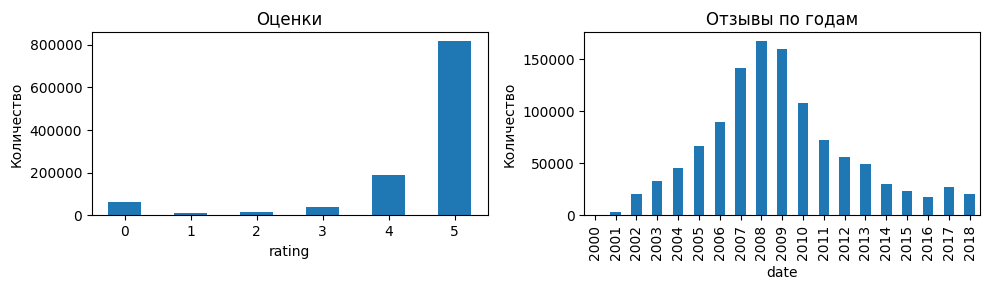

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
interactions.rating.value_counts().sort_index().plot.bar(
    ax=axes[0], rot=0, title='Оценки', ylabel='Количество',
)
pd.to_datetime(interactions.date).dt.year.value_counts().sort_index().plot.bar(
    ax=axes[1], title='Отзывы по годам', ylabel='Количество',
)
fig.tight_layout()
plt.show()

Для FM в качестве признаков будем использовать теги, время приготовления и число ингредиентов:

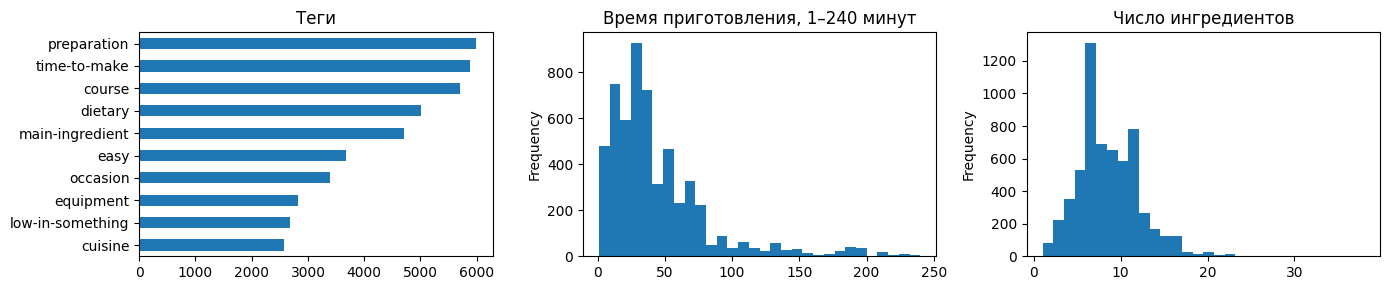

,minutes,n_steps,n_ingredients
count,5.993000e+03,5993.00,5993.00
mean,3.584178e+05,9.13,8.59
std,2.774008e+07,5.52,3.59
min,0.000000e+00,1.00,1.00
25%,2.000000e+01,5.00,6.00
50%,3.500000e+01,8.00,8.00
75%,6.000000e+01,11.00,11.00
max,2.147484e+09,82.00,38.00


In [15]:
from models.fm import parse_list

tag_counts = Counter(tag for tags in items.tags for tag in set(parse_list(tags)))
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
pd.Series(tag_counts).nlargest(10).sort_values().plot.barh(ax=axes[0], title='Теги')
items.loc[items.minutes.between(1, 240), 'minutes'].plot.hist(
    bins=30, ax=axes[1], title='Время приготовления, 1–240 минут',
)
items.n_ingredients.plot.hist(bins=30, ax=axes[2], title='Число ингредиентов')
fig.tight_layout()
plt.show()

display(items[['minutes', 'n_steps', 'n_ingredients']].describe().round(2))

### Метрики

Будем рекомендовать пользователям новые рецепты из каталога. Уже известные пользователю рецепты исключаем. Считаем положительным сигналом, если пользователь поставил эту рецепту оценку 4 и выше.

В качестве метрик выбраны recall@10 (показывает долю найденных релевантных рецептов) и NDCG@10 (показывает правильность их ранжирования). Так как в тестовой выборке у пользователя всего 1-2 положительных сигнала, метрика precision@k будет показывать заниженные значения. Итоговую метрику будем составлять как среднее по всем пользователям.

Параметры моделей выбираем на validation по NDCG@10. Затем обучаем модели на train + validation и считаем test.

Функции для подсчета метрик:

In [16]:
def recall_at_k(recommendations, relevant, k=10):
    relevant = set(relevant)
    if not relevant:
        return 0.0
    return len(set(recommendations[:k]) & relevant) / len(relevant)


def ndcg_at_k(recommendations, relevant, k=10):
    relevant = set(relevant)
    if not relevant:
        return 0.0
    seen = set()
    gains = []
    for item in recommendations[:k]:
        gains.append(float(item in relevant and item not in seen))
        seen.add(item)
    dcg = np.sum(np.asarray(gains) / np.log2(np.arange(len(gains)) + 2))
    idcg = np.sum(1 / np.log2(np.arange(min(k, len(relevant))) + 2))
    return float(dcg / idcg)

Проверим нужный сигнал в validation и test:

In [17]:
def evaluation_cohort(holdout, history, user_ids, item_ids):
    known = holdout.user_id.isin(user_ids) & holdout.recipe_id.isin(item_ids)
    seen = pd.MultiIndex.from_frame(history[['user_id', 'recipe_id']])
    pairs = pd.MultiIndex.from_frame(holdout[['user_id', 'recipe_id']])
    unseen = holdout[~pairs.isin(seen)]
    positives = unseen[unseen.rating >= 4].groupby('user_id').recipe_id.agg(set).to_dict()
    relevant = {user: positives.get(user, set()) for user in sorted(holdout.user_id.unique())}
    report = pd.Series({
        'holdout_interactions': len(holdout),
        'cold_users': holdout.loc[~holdout.user_id.isin(user_ids), 'user_id'].nunique(),
        'cold_items': holdout.loc[~holdout.recipe_id.isin(item_ids), 'recipe_id'].nunique(),
        'cold_interactions': int((~known).sum()),
        'seen_interactions': len(holdout) - len(unseen),
        'positive_interactions': int((unseen.rating >= 4).sum()),
        'evaluated_users': len(relevant),
        'users_with_positives': len(positives),
        'users_without_positives': len(relevant) - len(positives),
        'positive_interactions_outside_catalog': int(((unseen.rating >= 4) & ~unseen.recipe_id.isin(item_ids)).sum()),
    })
    return relevant, report

In [18]:
train_validation = pd.concat([train, validation], ignore_index=True)

validation_relevant, validation_report = evaluation_cohort(
    validation, train, train.user_id.unique(), train.recipe_id.unique(),
)
test_relevant, test_report = evaluation_cohort(
    test, train_validation,
    train_validation.user_id.unique(), train_validation.recipe_id.unique(),
)
display(pd.concat({'validation': validation_report, 'test': test_report}, axis=1))

,validation,test
holdout_interactions,11141,11119
cold_users,149,129
cold_items,27,52
cold_interactions,1031,1640
seen_interactions,0,0
positive_interactions,10560,10558
evaluated_users,2555,2100
users_with_positives,2494,2049
users_without_positives,61,51
positive_interactions_outside_catalog,254,804


Можно заметить, что в задаче есть и холодный старт: 129 новых пользователей и 52 новых рецепта в test. Это ограничивает метрики моделей. Сравнивать их между собой корректно, но при этом абсолютные значения могут быть занижены.

Для новых пользователей используем общий fallback по популярности:

In [19]:
def recommend_with_fallback(model, user_ids, history, timestamp, k=10):
    user_ids = np.asarray(user_ids)
    known = np.isin(user_ids, model.user_ids)
    result = np.full((len(user_ids), k), -1, dtype='int64')
    if known.any():
        result[known] = model.recommend(user_ids[known], k=k, seen=history, timestamp=timestamp)
    if (~known).any():
        counts = model.train[model.train.rating >= 4].groupby('recipe_id').size().reindex(model.item_ids, fill_value=0)
        order = model.item_ids[np.lexsort((model.item_ids, -counts.to_numpy()))]
        for row in np.flatnonzero(~known):
            seen = history.loc[history.user_id == user_ids[row], 'recipe_id']
            chosen = order[~np.isin(order, seen)][:k]
            result[row, :len(chosen)] = chosen
    return result

Все модели оцениваем одинаково. Время рекомендации — начало validation или test:

In [20]:
def evaluate(model, relevant, history, timestamp, k=10, batch_size=128):
    users = np.array(sorted(relevant), dtype='int64')
    if not len(users):
        raise ValueError('Нет пользователей в holdout')
    rows = []
    for start in range(0, len(users), batch_size):
        selected = users[start:start + batch_size]
        recommendations = recommend_with_fallback(model, selected, history, timestamp, k)
        for user, items in zip(selected, recommendations):
            rows.append((user, ndcg_at_k(items, relevant[user], k), recall_at_k(items, relevant[user], k), len(relevant[user])))
    per_user = pd.DataFrame(rows, columns=['user_id', f'ndcg@{k}', f'recall@{k}', 'relevant_items'])
    return per_user[[f'ndcg@{k}', f'recall@{k}']].mean().to_dict(), per_user

### Обучение моделей

Обучение моделей реализовано в `models/`. Здесь взаимодействие использует общий интерфейс fit/predict:

In [21]:
from models import ItemKNN, ALS, EASE, FM, TimeSVDpp

np.random.seed(SEED)
random.seed(SEED)

classes = {'ItemKNN': ItemKNN, 'ALS': ALS, 'EASE': EASE, 'FM': FM, 'TimeSVDpp': TimeSVDpp}
best_params, searches = {}, {}

Перебираем параметры и оставляем вариант с лучшим NDCG@10 на validation:

In [22]:
from tqdm import tqdm

def tune(model_class, grid, train, items, relevant, timestamp):
    rows = []
    combinations = list(itertools.product(*grid.values()))

    for values in tqdm(combinations, desc=model_class.__name__):
        params = dict(zip(grid, values))
        model = model_class(**params).fit(train, items)
        scores, _ = evaluate(model, relevant, train, timestamp)
        rows.append({'params': params, **scores})

    results = pd.DataFrame(rows).sort_values('ndcg@10', ascending=False, kind='stable', ignore_index=True)
    return results.loc[0, 'params'], results

### 1. ItemKNN

Считаем косинусное сходство рецептов по положительным оценкам. Рекомендуем рецепты, похожие на понравившиеся пользователю:

$$s_{ij}=\frac{X_i^TX_j}{\|X_i\|\|X_j\|}\frac{n_{ij}}{n_{ij}+h}$$

Здесь $X_{ui}=1$ при оценке от 4, $n_{ij}$ — число общих пользователей. На диагонали обнуляем, так как очевидно рецепт похож сам на себя. Подберём гиперпараметры:

In [23]:
grid = {'neighbors': [200, 800, 2000, 4000], 'shrink': [10, 100, 500, 2000]}

best_params['ItemKNN'], searches['ItemKNN'] = tune(
    ItemKNN, grid, train, items, validation_relevant, train_end,
)
display(searches['ItemKNN'])

,params,ndcg@10,recall@10
0,"{'neighbors': 2000, 'shrink': 500}",0.022621,0.032090
1,"{'neighbors': 2000, 'shrink': 2000}",0.022501,0.032009
2,"{'neighbors': 4000, 'shrink': 500}",0.022374,0.031993
3,"{'neighbors': 4000, 'shrink': 2000}",0.022350,0.031993
4,"{'neighbors': 4000, 'shrink': 100}",0.022231,0.031299
5,"{'neighbors': 2000, 'shrink': 100}",0.022152,0.031270
6,"{'neighbors': 200, 'shrink': 2000}",0.022105,0.029636
7,"{'neighbors': 800, 'shrink': 500}",0.022029,0.031449
8,"{'neighbors': 800, 'shrink': 2000}",0.022026,0.031058
9,"{'neighbors': 200, 'shrink': 500}",0.021992,0.029440


### 2. ALS

Предсказываем явный рейтинг. По данным видно, что оценки имеют сильное смещение в оценку 5, поэтому стоит использовать обобщение ALS со смещениями. Поочерёдно обновляем факторы пользователей и рецептов:

$$\hat r_{ui}=\mu+b_u+b_i+p_u^Tq_i,$$

здесь $\mu$ - средний рейтинг, $b_i, b_u$ - поправки пользователя и рецепта, $p_u, q_i$ - факторы.

Минимизируем ошибку на известных оценках:
$$L=\sum_{(u,i)\in\mathcal O}(r_{ui}-\hat r_{ui})^2+
\lambda(\|P\|_F^2+\|Q\|_F^2+\|b_u\|^2+\|b_i\|^2).$$

Подберём число факторов и регуляризацию:

In [24]:
grid = {'factors': [2, 4, 8, 16], 'reg': [0.5, 1, 2, 5], 'epochs': [15], 'seed': [SEED]}

best_params['ALS'], searches['ALS'] = tune(
    ALS, grid, train, items, validation_relevant, train_end,
)
display(searches['ALS'])

,params,ndcg@10,recall@10
0,"{'factors': 4, 'reg': 2, 'epochs': 15, 'seed': 42}",0.010035,0.011388
1,"{'factors': 16, 'reg': 2, 'epochs': 15, 'seed': 42}",0.008995,0.011726
2,"{'factors': 8, 'reg': 1, 'epochs': 15, 'seed': 42}",0.008692,0.011102
3,"{'factors': 8, 'reg': 2, 'epochs': 15, 'seed': 42}",0.008342,0.010511
4,"{'factors': 16, 'reg': 1, 'epochs': 15, 'seed': 42}",0.008090,0.010332
5,"{'factors': 16, 'reg': 5, 'epochs': 15, 'seed': 42}",0.007723,0.009155
6,"{'factors': 16, 'reg': 0.5, 'epochs': 15, 'seed': 42}",0.007370,0.009708
7,"{'factors': 4, 'reg': 5, 'epochs': 15, 'seed': 42}",0.007247,0.008658
8,"{'factors': 8, 'reg': 5, 'epochs': 15, 'seed': 42}",0.007059,0.008938
9,"{'factors': 2, 'reg': 5, 'epochs': 15, 'seed': 42}",0.007049,0.008832


### 3. EASE

Восстанавливаем положительные взаимодействия линейной моделью. Зануляем диагональ, что не иметь сигнал от того же рецепта:

$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\qquad B_{ii}=0.$$
$$P=(X^TX+\lambda I)^{-1},\qquad B_{ij}=-P_{ij}/P_{jj}\ (i\ne j).$$

Предсказания равны $XB$. Подбирём регуляризацию:

In [25]:
grid = {'reg': [10, 20, 50, 100, 200, 500, 1000, 2000, 3000, 5000, 10000, 20000, 50000, 100000, 500000, 1000000]}

best_params['EASE'], searches['EASE'] = tune(
    EASE, grid, train, items, validation_relevant, train_end,
)
display(searches['EASE'])

,params,ndcg@10,recall@10
0,{'reg': 2000},0.025378,0.036383
1,{'reg': 20000},0.024991,0.035877
2,{'reg': 10000},0.024974,0.035877
3,{'reg': 100000},0.024964,0.035872
4,{'reg': 50000},0.024961,0.035872
5,{'reg': 500000},0.024960,0.035872
6,{'reg': 1000000},0.024960,0.035872
7,{'reg': 3000},0.024936,0.035265
8,{'reg': 5000},0.024918,0.035706
9,{'reg': 1000},0.024308,0.033429


### 4. FM

Предсказываем рейтинг по user_ID, recipe_ID, тегам, времени приготовления и числу ингредиентов:

$$
\hat r(x)=w_0+\sum_j w_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k.
$$

Теги описывают национальность кухни и ограничения в продуктах, числовые признаки — сложность приготовления. Набор дополнительных факторов строим только по обучающей выборку. Обучаем SGD по квадрату ошибки с L2. Подбираем регуляризацию и число эпох:

In [26]:
grid = {'factors': [8, 16, 32, 64], 'reg': [0.001, 0.01, 0.1, 1], 'epochs': [3], 'lr': [0.005], 'seed': [SEED]}

best_params['FM'], searches['FM'] = tune(
    FM, grid, train, items, validation_relevant, train_end,
)
display(searches['FM'])

,params,ndcg@10,recall@10
0,"{'factors': 32, 'reg': 0.1, 'epochs': 3, 'lr': 0.005, 'seed': 42}",0.013432,0.015589
1,"{'factors': 32, 'reg': 1, 'epochs': 3, 'lr': 0.005, 'seed': 42}",0.011296,0.013309
2,"{'factors': 16, 'reg': 0.1, 'epochs': 3, 'lr': 0.005, 'seed': 42}",0.011046,0.015178
3,"{'factors': 32, 'reg': 0.01, 'epochs': 3, 'lr': 0.005, 'seed': 42}",0.010299,0.014194
4,"{'factors': 16, 'reg': 0.01, 'epochs': 3, 'lr': 0.005, 'seed': 42}",0.010175,0.013205
5,"{'factors': 16, 'reg': 0.001, 'epochs': 3, 'lr': 0.005, 'seed': 42}",0.007923,0.010155
6,"{'factors': 16, 'reg': 1, 'epochs': 3, 'lr': 0.005, 'seed': 42}",0.007678,0.011124
7,"{'factors': 8, 'reg': 1, 'epochs': 3, 'lr': 0.005, 'seed': 42}",0.007655,0.010308
8,"{'factors': 32, 'reg': 0.001, 'epochs': 3, 'lr': 0.005, 'seed': 42}",0.007170,0.010406
9,"{'factors': 8, 'reg': 0.1, 'epochs': 3, 'lr': 0.005, 'seed': 42}",0.006975,0.010479


### 5. timeSVD++

Добавляем к факторам пользователя его историю и временные компоненты. 

$$
\hat r_{ui}(t)=
\mu+
\underbrace{b_u(t)+b_i(t)}_{\text{склонность ставить и получать высокие оценки}}
+
q_i^T\left(
\underbrace{p_u(t)}_{\text{вкусы пользователя в момент }t}
+
\underbrace{\frac{1}{\sqrt{|N_u|}}\sum_{j\in N_u}y_j}_{\text{вклад его истории}}
\right).
$$

Здесь $\mu$ — средний рейтинг, $q_i$ — факторы рецепта, $N_u$ — рецепты из истории пользователя. Зависимость от $t$ позволяет учитывать изменение предпочтений со временем. Подберём регуляризацию и число эпох:

In [27]:
grid = {'factors': [8, 16, 32, 64], 'reg': [0.05, 0.2, 1, 2], 'epochs': [80], 'lr': [0.01], 'bin_days': [90], 'seed': [SEED]}

best_params['TimeSVDpp'], searches['TimeSVDpp'] = tune(
    TimeSVDpp, grid, train, items, validation_relevant, train_end,
)
display(searches['TimeSVDpp'])

,params,ndcg@10,recall@10
0,"{'factors': 32, 'reg': 0.2, 'epochs': 80, 'lr'...",0.006928,0.009257
1,"{'factors': 64, 'reg': 0.2, 'epochs': 80, 'lr'...",0.006693,0.008959
2,"{'factors': 16, 'reg': 0.2, 'epochs': 80, 'lr'...",0.006599,0.008558
3,"{'factors': 8, 'reg': 0.2, 'epochs': 80, 'lr':...",0.006188,0.008926
4,"{'factors': 64, 'reg': 0.05, 'epochs': 80, 'lr...",0.005947,0.007083
5,"{'factors': 16, 'reg': 0.05, 'epochs': 80, 'lr...",0.005712,0.007132
6,"{'factors': 8, 'reg': 0.05, 'epochs': 80, 'lr'...",0.005625,0.007217
7,"{'factors': 8, 'reg': 2, 'epochs': 80, 'lr': 0...",0.005615,0.006327
8,"{'factors': 16, 'reg': 2, 'epochs': 80, 'lr': ...",0.005615,0.006327
9,"{'factors': 32, 'reg': 2, 'epochs': 80, 'lr': ...",0.005615,0.006327


### Сравнение моделей

Обучаем модели заново на train + validation. Считаем метрики на test:

In [29]:
records, per_user, histories = [], {}, {}

for name, cls in classes.items():
    started = perf_counter()
    model = cls(**best_params[name]).fit(train_validation, items)
    fit_seconds = perf_counter() - started

    started = perf_counter()
    scores, per_user[name] = evaluate(model, test_relevant, train_validation, validation_end)
    predict_seconds = perf_counter() - started

    records.append({'model': name, **scores, 'fit_seconds': fit_seconds,
                    'predict_seconds': predict_seconds, 'params': best_params[name]})
    if hasattr(model, 'history'):
        histories[name] = model.history

results = pd.DataFrame(records).sort_values('ndcg@10', ascending=False).reset_index(drop=True)
display(results)

,model,ndcg@10,recall@10,fit_seconds,predict_seconds,params
0,EASE,0.021293,0.032013,13.234515,10.989696,{'reg': 2000}
1,ItemKNN,0.020203,0.029069,17.798550,3.807533,"{'neighbors': 2000, 'shrink': 500}"
2,FM,0.008497,0.012219,1.202558,1.380464,"{'factors': 32, 'reg': 0.1, 'epochs': 3, 'lr':..."
3,ALS,0.007303,0.010647,8.577603,1.272201,"{'factors': 4, 'reg': 2, 'epochs': 15, 'seed':..."
4,TimeSVDpp,0.004575,0.005903,18.964790,1.256442,"{'factors': 32, 'reg': 0.2, 'epochs': 80, 'lr'..."


Сравним NDCG@10 и Recall@10 на графике:

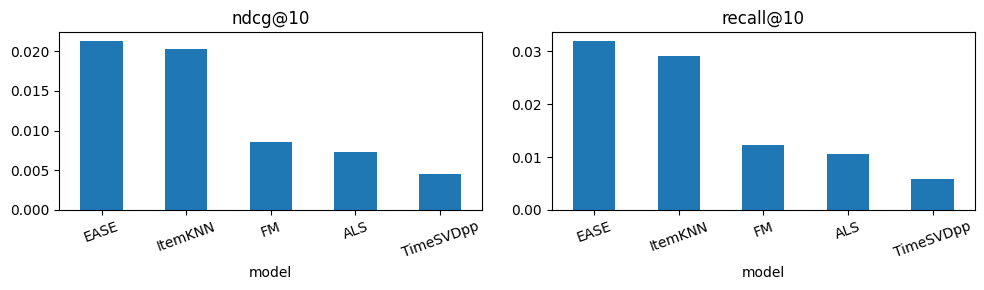

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for metric, ax in zip(['ndcg@10', 'recall@10'], axes):
    results.set_index('model')[metric].plot.bar(ax=ax, rot=20, title=metric)
    ax.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

Отдельно посмотрим на пользователей хотя бы с одной положительной оценкой:

In [31]:
positive_results = []
for name in results.model:
    frame = per_user[name].query('relevant_items > 0')
    scores = frame[['ndcg@10', 'recall@10']].mean().to_dict()
    positive_results.append({'model': name, **scores})

display(pd.DataFrame(positive_results))

,model,ndcg@10,recall@10
0,EASE,0.021823,0.032810
1,ItemKNN,0.020706,0.029792
2,FM,0.008708,0.012523
3,ALS,0.007485,0.010912
4,TimeSVDpp,0.004689,0.006050


### Выводы

Лучшие результаты получились у EASE: NDCG@10 = 0.0213, Recall@10 = 0.0320.

Следующая лучшая модель - ItemKNN.

Можно заметить, что из-за простоты данных сложные модели вида FM или timeSVD++ не дают лучших метрик. ALS, FM и timeSVD++ предсказывают конкретные численные оценки, из-за чего ошибаются чаще, чем простые модели, пытающиеся предсказать положительное взаимодействие. 

При этом, предсказание с помощью EASE занимает большое время относительно всех остальных моделей, так что при расширении датасета до реальных значений в сотни тысяч и миллионы рецептов EASE может стать не поддерживаемой моделью. Тогда более практичной станет ItemKNN, даже если метрики будут несколько хуже EASE.